### Staffing a Bakery
How many staff members does a bakery need behind the counter during the morning rush?

Consider the bakery’s typical 7–9am rush:<br>
- Approximately 84 customers per hour<br>
- Around 2 minutes to serve each customer<br>

However, customer arrivals are uneven. Five might walk in at once, followed by three minutes without a customer. Service times also vary, ranging from 30 seconds to 5 minutes.

In [1]:
library(ggplot2)

In [2]:
# Inputs
customers_per_hour <- 84  
service_minutes <- 2      
rush_minutes <- 120      
staff_options <- 3:6      
long_wait <- 5           
n_mornings <- 1000       
set.seed(2026)

In [3]:
# Simulate a single morning
simulate_morning <- function(staff) {
  rate <- customers_per_hour/60               # arrivals per minute
  n <- rpois(1,rate*rush_minutes)             # customers this morning
  arrive <- sort(runif(n,0,rush_minutes))     # random arrival times
  service <- rexp(n,rate = 1/service_minutes) # random service times
  free_at <- rep(0,staff)                     # when each server is next free
  wait <- numeric(n)
  for (i in seq_len(n)) {                     # first come, first served
    k <- which.min(free_at)
    start <- max(arrive[i],free_at[k])
    wait[i] <- start-arrive[i]
    free_at[k] <- start+service[i]
  }
  wait
}

# Simulation 1000 mornings
results <- do.call(rbind,lapply(staff_options,function(s) {
  waits <- unlist(replicate(n_mornings,simulate_morning(s),simplify = FALSE))
  data.frame(
    staff = s,
    utilisation_pct = 100*(customers_per_hour/60)*service_minutes/s,
    avg_wait = mean(waits),
    pct_long = 100*mean(waits > long_wait)
  )
}))

print(transform(results,utilisation_pct = round(utilisation_pct),avg_wait = round(avg_wait,1),
                pct_long = round(pct_long)),row.names = FALSE)

 staff utilisation_pct avg_wait pct_long
     3              93      3.9       29
     4              70      0.6        2
     5              56      0.2        0
     6              47      0.0        0


Simulating 1,000 mornings reveal:<br>
With 3 staff (93% utilisation)<br>
- Average waiting time: 3.9 minutes<br>
- 29% of customers wait more than 5 minutes<br>

With 4 staff (70% utilisation)<br>
- Average waiting time: 0.6 minutes<br>
- Only 2% of customers wait more than 5 minutes<br>

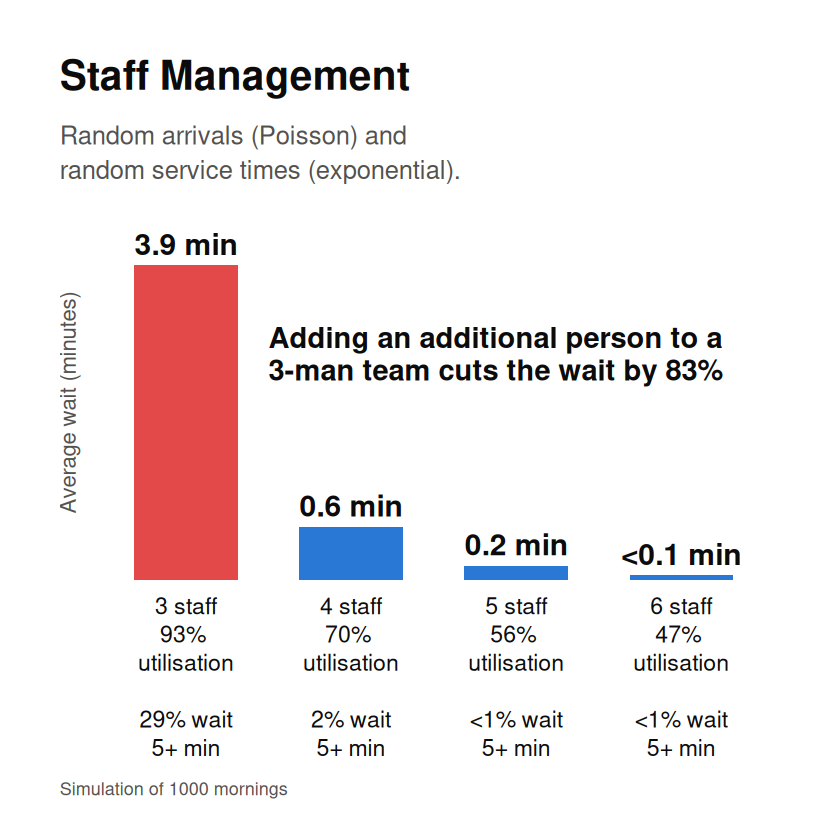

In [6]:
# Chart
blue <- "#2a78d6"
red <- "#e34948"
ink <- "#0b0b0b"
ink2 <- "#52514e"

results$label_top <- ifelse(results$avg_wait < 0.05,"<0.1 min",
                            sprintf("%.1f min",results$avg_wait))
results$long_txt <- ifelse(results$pct_long < 1,"<1%",
                            sprintf("%.0f%%",results$pct_long))
results$label_bot <- sprintf("%d staff\n%.0f%% \nutilisation\n\n%s wait\n%d+ min",
                             results$staff,results$utilisation_pct,
                             results$long_txt,long_wait)
results$too_busy <- results$utilisation_pct > 85
top <- max(results$avg_wait)

first  <- results[1, ]
second <- results[2, ]

ggplot(results,aes(x = factor(staff),y = avg_wait,fill = too_busy)) +
geom_col(width = 0.62) +
geom_text(aes(label = label_top),vjust = -0.5,size = 6.2,
          fontface = "bold",colour = ink) +
scale_fill_manual(values = c(`FALSE` = blue,`TRUE` = red),guide = "none") +
scale_x_discrete(labels = results$label_bot) +
scale_y_continuous(expand = expansion(mult = c(0.02, 0.15))) +
annotate("text",x = 1.5,y = top*0.72,hjust = 0,
         label = sprintf("Adding an additional person to a \n3-man team cuts the wait by %.0f%%",
                         100*(1-second$avg_wait/first$avg_wait)),
         size = 6,fontface = "bold",colour = ink,lineheight = 0.95) +
labs(title = "Staff Management",
     subtitle = sprintf(paste0("Random arrivals (Poisson) and\n",
                               "random service times (exponential).")),
     x = NULL,y = "Average wait (minutes)",caption = "Simulation of 1000 mornings") +
theme_minimal(base_size = 15) +
theme(plot.background = element_rect(fill = "white",colour = NA),
      plot.title = element_text(face = "bold",size = 24,colour = ink,lineheight = 1.05),
      plot.subtitle = element_text(size = 15,colour = ink2,lineheight = 1.15,
                                   margin = margin(t = 8,b = 20)),
      plot.caption = element_text(size = 10.5,colour = ink2,hjust = 0,
                                  margin = margin(t = 14)),
      plot.title.position = "plot",
      plot.caption.position = "plot",
      axis.title.y = element_text(colour = ink2,size = 13),
      axis.text.x = element_text(colour = ink, size = 13.5,lineheight = 1.05,
                                 margin = margin(t = 6)),
      axis.text.y = element_blank(),
      panel.grid = element_blank(),
      plot.margin = margin(36,36,24,36))

While adding a fourth staff member reduces average waiting time by 83%, a fifth makes little difference.

The optimal staffing level lies at the point where the additional benefit of another employee no longer justifies the extra cost.